# 02 · Fase A — Teardown de DETR-R50
Parámetros y FLOPs por bloque, latencia/memoria, características intermedias, mapas de atención, campo receptivo, línea base en COCO y **costo en función de N (H3)**.
*FLOPs = 2 × MACs (convención de `torch.utils.flop_counter`).*

In [1]:
import os, sys, subprocess
REPO_URL = 'https://github.com/OscarLauLu/DETR-1INF52.git'
BRANCH   = 'rodrigo_dev'               # main aún no tiene el avance
REPO_DIR = 'DETR-1INF52'
if not os.path.exists('../src/common.py'):
    if not os.path.exists(f'{REPO_DIR}/src'):
        !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
    os.chdir(f'{REPO_DIR}/notebooks')
    !pip -q install -r ../requirements.txt
sys.path.insert(0, '../src')
from common import *
import torch, json, pandas as pd, matplotlib.pyplot as plt
os.makedirs('../results', exist_ok=True); os.makedirs('../data', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'; SEED = 42; set_seed(SEED)
COMMIT = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print(DEVICE, '| commit', COMMIT); print(env_report('../results/entorno.txt'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
cuda | commit 62b1186
python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
torch 2.11.0+cu128
torchvision 0.26.0+cu128
transformers 4.57.6
timm 1.0.29
pycocotools ?
scipy 1.16.3
numpy 2.1.3
GPU Tesla T4 | CUDA 12.8


In [2]:
print(torch.__version__, torch.version.cuda, torch.cuda.get_device_name(0), torch.cuda.get_device_capability(0))
x = torch.randn(2, 3, 64, 64, device='cuda')
print(torch.nn.functional.relu(torch.nn.Conv2d(3, 8, 3).cuda()(x)).sum().item())

2.11.0+cu128 12.8 Tesla T4 (7, 5)
13609.0908203125


In [3]:
# Rutas de la copia de Kaggle de VisDrone (ajusta tras revisar el árbol en 01)
ROOT = '/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset'
TRAIN_IMG, TRAIN_LBL = f'{ROOT}/VisDrone2019-DET-train/images', f'{ROOT}/VisDrone2019-DET-train/labels'
VAL_IMG,   VAL_LBL   = f'{ROOT}/VisDrone2019-DET-val/images',   f'{ROOT}/VisDrone2019-DET-val/labels'

from transformers import DetrForObjectDetection, DetrImageProcessor
from PIL import Image
CKPT = 'facebook/detr-resnet-50'
processor = DetrImageProcessor.from_pretrained(CKPT)          # resolución original (lado corto 800)
model = DetrForObjectDetection.from_pretrained(CKPT).to(DEVICE).eval()
# Imagen de ejemplo: la más densa de validación
cnt = objects_per_image('../data/val_sub.json'); vd = json.load(open('../data/val_sub.json'))
dense = max(vd['images'], key=lambda im: cnt[im['id']]); print(dense['file_name'], cnt[dense['id']], 'objetos')
img = Image.open(os.path.join(VAL_IMG, dense['file_name'])).convert('RGB'); enc = processor(images=img, return_tensors='pt')
pv, pm = enc['pixel_values'].to(DEVICE), enc['pixel_mask'].to(DEVICE); print(pv.shape)

preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  module._load_from_state_dict(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/batchnorm.py:133: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  super()._load_from_state_dict(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/batchnorm.py:133: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, whi

0000295_02400_d_0000033.jpg 317 objetos
torch.Size([1, 3, 750, 1333])


## A1 · Parámetros por bloque

In [4]:
blocks = {'backbone (ResNet-50)': model.model.backbone, 'input_projection': model.model.input_projection,
          'query_embeddings': model.model.query_position_embeddings, 'encoder (6 capas)': model.model.encoder,
          'decoder (6 capas)': model.model.decoder, 'class head': model.class_labels_classifier, 'box head (MLP)': model.bbox_predictor}
P = pd.DataFrame([(k, sum(p.numel() for p in m.parameters())) for k, m in blocks.items()], columns=['bloque', 'parámetros'])
P['%'] = (100 * P['parámetros'] / P['parámetros'].sum()).round(1); print(P)
print('suma bloques', P['parámetros'].sum(), '| total modelo', count_params(model))   # deben coincidir
P.to_csv('../results/params_por_bloque.csv', index=False)

                 bloque  parámetros     %
0  backbone (ResNet-50)    23454912  56.5
1      input_projection      524544   1.3
2      query_embeddings       25600   0.1
3     encoder (6 capas)     7890432  19.0
4     decoder (6 capas)     9473024  22.8
5            class head       23644   0.1
6        box head (MLP)      132612   0.3
suma bloques 41524768 | total modelo 41524768


## A2 · FLOPs por bloque

In [5]:
from torch.utils.flop_counter import FlopCounterMode
with torch.no_grad(), FlopCounterMode(depth=4, display=False) as fc: model(pixel_values=pv, pixel_mask=pm)
counts = {k: sum(v.values()) for k, v in fc.get_flop_counts().items()}
for k, v in counts.items(): print(f'{v/1e9:9.2f} GFLOPs  {k}')   # revisa los nombres y ajusta los filtros si hace falta
rows = []
for key in ['model.backbone', 'model.input_projection', 'model.encoder', 'model.decoder', 'class_labels_classifier', 'bbox_predictor']:
    rows.append((key, sum(v for k, v in counts.items() if k.endswith(key)) / 1e9))
total = fc.get_total_flops() / 1e9
F = pd.DataFrame(rows, columns=['bloque', 'GFLOPs']); F['%'] = (100 * F['GFLOPs'] / total).round(1)
print(F, '\ntotal', round(total, 2), 'GFLOPs | suma de bloques', round(F['GFLOPs'].sum(), 2), '| entrada', tuple(pv.shape))
F.to_csv('../results/flops_por_bloque.csv', index=False)

   164.78 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder
   191.93 GFLOPs  DetrForObjectDetection.model
   164.78 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model
   191.96 GFLOPs  DetrForObjectDetection
   191.96 GFLOPs  Global
   164.78 GFLOPs  DetrForObjectDetection.model.backbone
     4.71 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.conv1
     0.51 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1.0.conv1
     9.26 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1.0
    26.75 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1
     4.63 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1.0.conv2
     2.06 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1.0.conv3
     2.06 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.model.layer1.0.downsample.0
     2.06 GFLOPs  DetrForObjectDetection.model.backbone.conv_encoder.mode

## A3 · Latencia y memoria (calentamiento + repeticiones)

In [6]:
import time
assert DEVICE == 'cuda', 'medir latencia en GPU'
torch.cuda.reset_peak_memory_stats()
lat = latency_ms(model, pv, pm, runs=30, warmup=10)
# por bloque (aprox.): hooks con sincronización; se retiran al terminar
times, handles = {}, []
def mk(name):
    def pre(m, i): torch.cuda.synchronize(); times[name] = -time.perf_counter()
    def post(m, i, o): torch.cuda.synchronize(); times[name] += time.perf_counter()
    return pre, post
for name, m in {'backbone': model.model.backbone, 'encoder': model.model.encoder, 'decoder': model.model.decoder}.items():
    a, b = mk(name); handles += [m.register_forward_pre_hook(a), m.register_forward_hook(b)]
with torch.no_grad(): model(pixel_values=pv, pixel_mask=pm)
for h in handles: h.remove()
print(f'latencia total {lat:.1f} ms | memoria pico {torch.cuda.max_memory_allocated()/2**20:.0f} MiB (incluye pesos)')
print({k: round(v * 1000, 1) for k, v in times.items()}, 'ms (una pasada, aprox.)')
pd.DataFrame([{'latencia_ms': lat, 'mem_pico_MiB': torch.cuda.max_memory_allocated() / 2**20,
               **{f'{k}_ms': v * 1000 for k, v in times.items()}, 'entrada': tuple(pv.shape)}]).to_csv('../results/latencia_memoria.csv', index=False)

latencia total 83.5 ms | memoria pico 461 MiB (incluye pesos)
{'backbone': 66.1, 'encoder': 13.2, 'decoder': 7.9} ms (una pasada, aprox.)


## A4 · Características intermedias del backbone

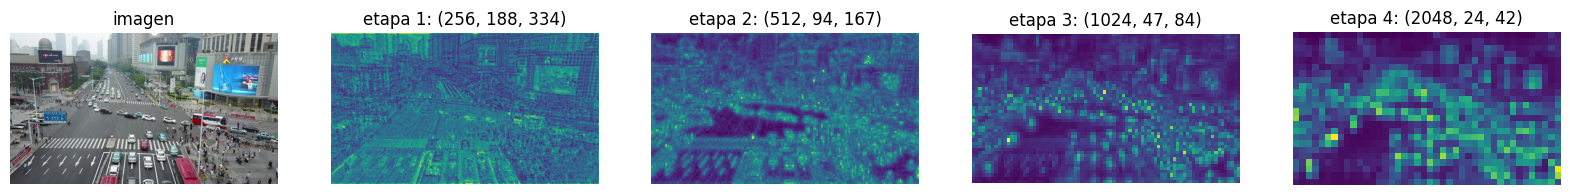

In [7]:
with torch.no_grad(): feats = model.model.backbone.conv_encoder(pv, pm)
fig, ax = plt.subplots(1, len(feats) + 1, figsize=(4 * (len(feats) + 1), 4)); ax[0].imshow(img); ax[0].set_title('imagen')
for i, (f, _) in enumerate(feats): ax[i + 1].imshow(f[0].mean(0).cpu(), cmap='viridis'); ax[i + 1].set_title(f'etapa {i+1}: {tuple(f.shape[1:])}')
for a in ax: a.axis('off')
plt.savefig('../results/features_intermedias.png', dpi=150, bbox_inches='tight')

## A5 · Mapas de atención del decoder (última capa, queries con mayor score)

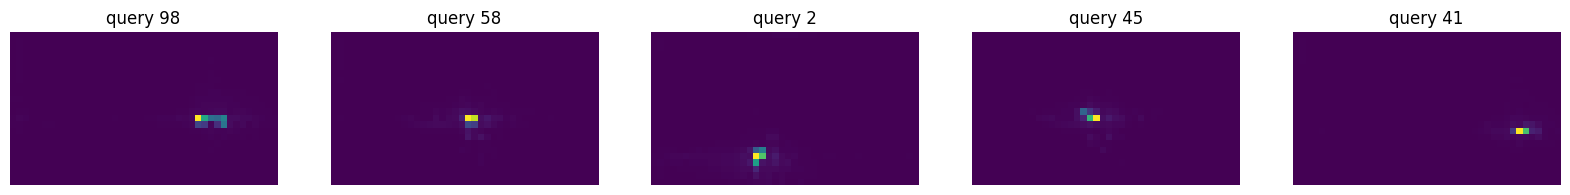

In [8]:
with torch.no_grad(): out = model(pixel_values=pv, pixel_mask=pm, output_attentions=True)
(features, _) = model.model.backbone(pv, pm); h, w = features[-1][0].shape[-2:]
att = out.cross_attentions[-1][0].mean(0)             # (queries, h*w), promedio de cabezas
top = out.logits[0].softmax(-1)[:, :-1].max(-1).values.topk(5).indices.tolist()
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, q in zip(ax, top): a.imshow(att[q].reshape(h, w).cpu()); a.set_title(f'query {q}'); a.axis('off')
plt.savefig('../results/atencion_decoder.png', dpi=150, bbox_inches='tight')

## A6 · Campo receptivo: efectivo (por gradiente) vs teórico
Teórico en la salida de `layer4` (stride 32): **427 px**. El backbone de DETR en Hugging Face es el `resnet50` de timm (ResNet v1.5: stride en la conv 3×3).
El valor de 483 px que se cita a veces corresponde a ResNet v1 (stride en la primera 1×1). Cálculo: r ← r + (k−1)·j, j ← j·s, capa por capa.

teórico v1.5 (timm): (427, 32) | v1: (483, 32)
extensión efectiva (>5% del máx) ≈ 200 x 182 px  vs teórico 427


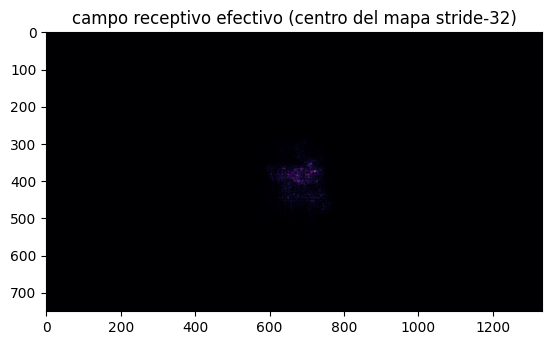

In [9]:
def rf_resnet50(stride_on_3x3=True):
    r, j = 1, 1
    for k, s in [(7, 2), (3, 2)]: r += (k - 1) * j; j *= s           # conv1, maxpool
    for blocks, stride in [(3, 1), (4, 2), (6, 2), (3, 2)]:
        for b in range(blocks):
            s = stride if b == 0 else 1
            for k, st in ([(1, 1), (3, s), (1, 1)] if stride_on_3x3 else [(1, s), (3, 1), (1, 1)]):
                r += (k - 1) * j; j *= st
    return r, j
print('teórico v1.5 (timm):', rf_resnet50(True), '| v1:', rf_resnet50(False))   # (427, 32) y (483, 32)

x = pv.clone().requires_grad_(True)
fm = model.model.backbone(x, pm)[0][-1][0]; cy, cx = fm.shape[-2] // 2, fm.shape[-1] // 2
fm[0, :, cy, cx].sum().backward()
erf = x.grad.abs().sum(1)[0].cpu(); plt.imshow(erf, cmap='magma'); plt.title('campo receptivo efectivo (centro del mapa stride-32)')
plt.savefig('../results/campo_receptivo.png', dpi=150, bbox_inches='tight')
ys, xs = torch.where(erf > erf.max() * 0.05); print('extensión efectiva (>5% del máx) ≈', (ys.max() - ys.min()).item(), 'x', (xs.max() - xs.min()).item(), 'px  vs teórico 427')

## A7 · Reproducción de la línea base en COCO val2017 (subconjunto)
Descarga val2017 + anotaciones (Colab) y evalúa 500 imágenes. Referencia: AP = 42.0 en el val completo (Carion et al., 2020). Documenta la diferencia (subconjunto de 500 → varía unos puntos).

In [10]:
!wget -q http://images.cocodataset.org/zips/val2017.zip -P /tmp && unzip -q -o /tmp/val2017.zip -d /tmp
!wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -P /tmp && unzip -q -o /tmp/annotations_trainval2017.zip -d /tmp
!ln -sfn /tmp/val2017 ../data/val2017 && ln -sfn /tmp/annotations ../data/annotations
print(make_subset('../data/annotations/instances_val2017.json', 500, '../data/coco_val_sub.json', SEED))
dets = predict(model, processor, '../data/val2017', '../data/coco_val_sub.json', device=DEVICE, label_offset=0)   # etiquetas = ids COCO
base = coco_eval('../data/coco_val_sub.json', dets); print({k: round(v, 3) for k, v in base.items()})
pd.DataFrame([base]).to_csv('../results/linea_base_coco.csv', index=False)

{'imagenes': 500, 'cajas': 3245, 'cajas_por_imagen': 6.5}
{'AP': 0.456, 'AP50': 0.65, 'AP75': 0.48, 'AP_S': 0.221, 'AP_M': 0.504, 'AP_L': 0.675, 'AP@500': 0.456, 'AR@100': 0.592, 'AR@500': 0.592, 'AR_S@500': 0.313, 'AR_M@500': 0.65, 'AR_L@500': 0.84, 'n_img': 500}


## A8 · Costo en función del número de queries (H3)
Mismo input que la ablación (lado corto 512). Solo cambia N; los pesos no importan para el costo.

In [11]:
proc512 = DetrImageProcessor.from_pretrained(CKPT, size={'shortest_edge': 512, 'longest_edge': 853})
e = proc512(images=img, return_tensors='pt'); pv5, pm5 = e['pixel_values'].to(DEVICE), e['pixel_mask'].to(DEVICE)
print('entrada', tuple(pv5.shape))
rows = []
for N in (100, 300, 500):
    base = torch.cuda.memory_allocated()                     # lo que ya ocupan las celdas anteriores
    m = build_model(num_queries=N, num_labels=10).to(DEVICE).eval()
    pesos = (torch.cuda.memory_allocated() - base) / 2**20   # memoria de los pesos de esta variante
    torch.cuda.reset_peak_memory_stats()
    gflops = flops_total(m, pv5, pm5) / 1e9
    lat = latency_ms(m, pv5, pm5)
    pico = (torch.cuda.max_memory_allocated() - base) / 2**20  # pesos + activaciones de esta variante
    rows.append({'N': N, 'params_M': count_params(m) / 1e6, 'GFLOPs': gflops, 'latencia_ms': lat,
                 'mem_pesos_MiB': pesos, 'mem_pico_MiB': pico})
    del m; torch.cuda.empty_cache()
H3 = pd.DataFrame(rows)
H3['ΔGFLOPs vs 100 (%)'] = (100 * (H3['GFLOPs'] / H3['GFLOPs'][0] - 1)).round(2)
H3['Δlatencia vs 100 (%)'] = (100 * (H3['latencia_ms'] / H3['latencia_ms'][0] - 1)).round(2)
print(H3.round(2)); H3.to_csv('../results/costo_vs_N.csv', index=False)

entrada (1, 3, 480, 853)


Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DetrForObjectDetection were not initialized from the model checkpoin

     N  params_M  GFLOPs  latencia_ms  mem_pesos_MiB  mem_pico_MiB  \
0  100     41.50   77.77        39.03         159.99        267.22   
1  300     41.56   82.28        41.69         160.93        271.21   
2  500     41.61   87.27        44.96         161.13        271.40   

   ΔGFLOPs vs 100 (%)  Δlatencia vs 100 (%)  
0                0.00                  0.00  
1                5.79                  6.80  
2               12.21                 15.18  
